# Does a topographic metric distinguish organized from random unit layouts?

| | |
| --- | --- |
| **Question** | Does the topographic alignment metric give a higher score to a layout in which nearby units respond alike than to a layout with no spatial structure? |
| **Requires** | CPU only; NumPy, SciPy, matplotlib. No downloads. A few seconds. |
| **Lessons used** | [5. Layers and regions](../lessons/05_layers_and_regions.ipynb), [2. Your first benchmark](../lessons/02_your_first_benchmark.ipynb) |

## Background

In visual cortex, neighboring neurons tend to have similar response properties, so the
correlation between two units' responses falls with the distance between them. A model
whose units have spatial positions can be compared with cortex on this property,
independently of how well it predicts individual responses. Before such a metric is
applied to real models and recordings, it should be checked on data where the answer is
known.

All responses and positions in this notebook are synthetic, including the target that
stands in for cortex.

## Hypothesis

A spatially smoothed layout will have positive spatial smoothness and a correlation that
decreases with distance, and it will align with a second smoothed layout more closely than
a random layout does.

## Method

Each layout places 256 units on a 16 by 16 grid and records their responses to 60
stimuli. The organized layout is Gaussian noise blurred across the grid, so neighboring
units share signal. The random layout uses unblurred noise, so position carries no
information. Unit positions are scaled to the range 0 to 1.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from brainscore.metrics.topographic import (spatial_smoothness,
    correlation_distance_profile, topographic_alignment)

def grid_positions(g):
    rows, cols = np.meshgrid(np.arange(g), np.arange(g), indexing='ij')
    return np.stack([rows.ravel(), cols.ravel()], -1) / (g - 1)

def organized_layout(n_stimuli=60, g=16, seed=0, sigma=2.0):
    rng = np.random.RandomState(seed)
    responses = np.stack([gaussian_filter(rng.randn(g, g), sigma, mode='reflect').ravel()
                          for _ in range(n_stimuli)])
    return responses, grid_positions(g)

def random_layout(n_stimuli=60, g=16, seed=0):
    return np.random.RandomState(seed).randn(n_stimuli, g * g), grid_positions(g)

organized, organized_pos = organized_layout()
random_resp, random_pos = random_layout()
target, target_pos = organized_layout(seed=1)   # synthetic stand-in for cortex

Three measures are computed. Spatial smoothness summarizes how strongly response
similarity tracks spatial proximity. The correlation-distance profile averages the
response correlation of unit pairs in 12 distance bins. Topographic alignment correlates a
layout's profile with the target's profile.

In [2]:
smooth = {'organized': spatial_smoothness(organized, organized_pos),
          'random': spatial_smoothness(random_resp, random_pos)}
profiles = {'organized': correlation_distance_profile(organized, organized_pos, n_bins=12),
            'random': correlation_distance_profile(random_resp, random_pos, n_bins=12)}
alignment = {
    'organized': float(topographic_alignment(organized, organized_pos, target, target_pos, n_bins=12)[0]),
    'random': float(topographic_alignment(random_resp, random_pos, target, target_pos, n_bins=12)[0]),
}

## Results

In [3]:
for name in smooth:
    print(f'{name:9s} smoothness {smooth[name]:+.3f}   alignment to target {alignment[name]:+.3f}')

organized smoothness +0.649   alignment to target +0.996
random    smoothness -0.004   alignment to target +0.086


The organized layout has smoothness 0.649 and alignment 0.996 with the target. The
random layout has smoothness -0.004 and alignment 0.086.

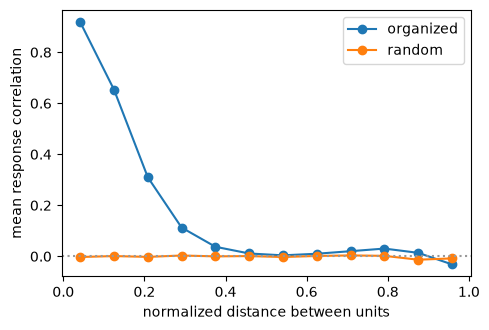

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.4))
for name, (x, y, _) in profiles.items():
    ax.plot(x, y, '-o', label=name)
ax.axhline(0, ls=':', c='0.6')
ax.set_xlabel('normalized distance between units')
ax.set_ylabel('mean response correlation')
ax.legend()
fig.tight_layout()
plt.show()

In the organized layout, correlation is high for nearby units and falls with
distance. In the random layout it is near zero at every distance.

## Conclusion and limits

The metric separates a layout with built-in spatial structure from one without it, which
is the minimum requirement for using it on real data. This check does not show that the
metric is sensitive to subtler differences between models, and the target here is a
synthetic layout, not cortex.

On measured data, the target profile is computed from recorded responses and the cortical
surface coordinates of the recording sites. The model must provide a position for every
unit; models without unit positions cannot be scored with this metric.

[Lessons](../lessons/) · [Documentation](../../docs/README.md)